
# JWST/MIRI Spectral Quality Control Pipeline

## Project Overview

This notebook develops a lightweight, automated quality-control (QC) workflow for JWST/MIRI Medium Resolution Spectroscopy (MRS) data.

The goal is to identify potentially suspicious spectral features, such as sharp spikes or dips, without requiring full reprocessing of the original observational dataset.

Rather than analyzing all available JWST data (>100 GB), this pipeline will initially work with smaller, already-processed Stage 3 X1D spectra.

### Main Objectives

1. Load and inspect existing JWST/MIRI X1D spectra.
2. Automatically identify unusual spectral features.
3. Compare detected features with existing data-quality (DQ) flags and flux uncertainties.
4. Test the method on different MIRI wavelength settings.
5. Generate visualizations and summaries of potential quality issues.
6. Identify cases that may require further investigation using Stage 2 CAL or Stage 3 S3D products.

### Initial Test Case

The first test will use the Channel 1 Long spectrum explored in `01_irs3_data_exploration.ipynb`.

Previous analysis identified a narrow flux decrease near 7.065 μm that was not flagged in the extracted X1D spectrum.

This feature will serve as an initial test case for evaluating whether an automated method can identify suspicious spectral behavior.

**Important:** A detected anomaly is not necessarily an instrumental artifact. The pipeline will flag features for further investigation rather than automatically classify them as errors.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from pathlib import Path


## 1. Loading the Test Spectrum

I will begin with the JWST/MIRI Channel 1 Long X1D file used in the exploratory analysis.

This file contains wavelength, flux, flux uncertainty, and data-quality information.

I will load only the EXTRACT1D table rather than the larger Stage 3 spectral cube or Stage 2 detector products.

This allows us to develop and test the QC method using a smaller data product.


In [12]:
# Directory containing JWST/MIRI data
data_dir = Path("data/IRS3")

# Channel 1 Long spectrum
x1d_file = data_dir / "jw01266-o009_t002_miri_ch1-long_x1d.fits"

# Confirm the file exists
if not x1d_file.exists():
    raise FileNotFoundError(f"Cannot find: {x1d_file.resolve()}")

# Read the extracted spectrum
with fits.open(x1d_file, memmap=True) as hdul:
    spectrum = hdul["EXTRACT1D"].data

    wavelength = np.array(spectrum["WAVELENGTH"], dtype=np.float64)
    flux = np.array(spectrum["FLUX"], dtype=np.float64)
    flux_error = np.array(spectrum["FLUX_ERROR"], dtype=np.float64)
    dq = np.array(spectrum["DQ"], dtype=np.int64)

print("File:", x1d_file.name)
print("Number of wavelength points:", len(wavelength))
print(f"Wavelength range: {wavelength.min():.3f} - {wavelength.max():.3f} µm")
print("Number of non-finite flux values:", np.sum(~np.isfinite(flux)))
print("Number of points with DQ != 0:", np.sum(dq != 0))


File: jw01266-o009_t002_miri_ch1-long_x1d.fits
Number of wavelength points: 1400
Wavelength range: 6.530 - 7.650 µm
Number of non-finite flux values: 0
Number of points with DQ != 0: 0


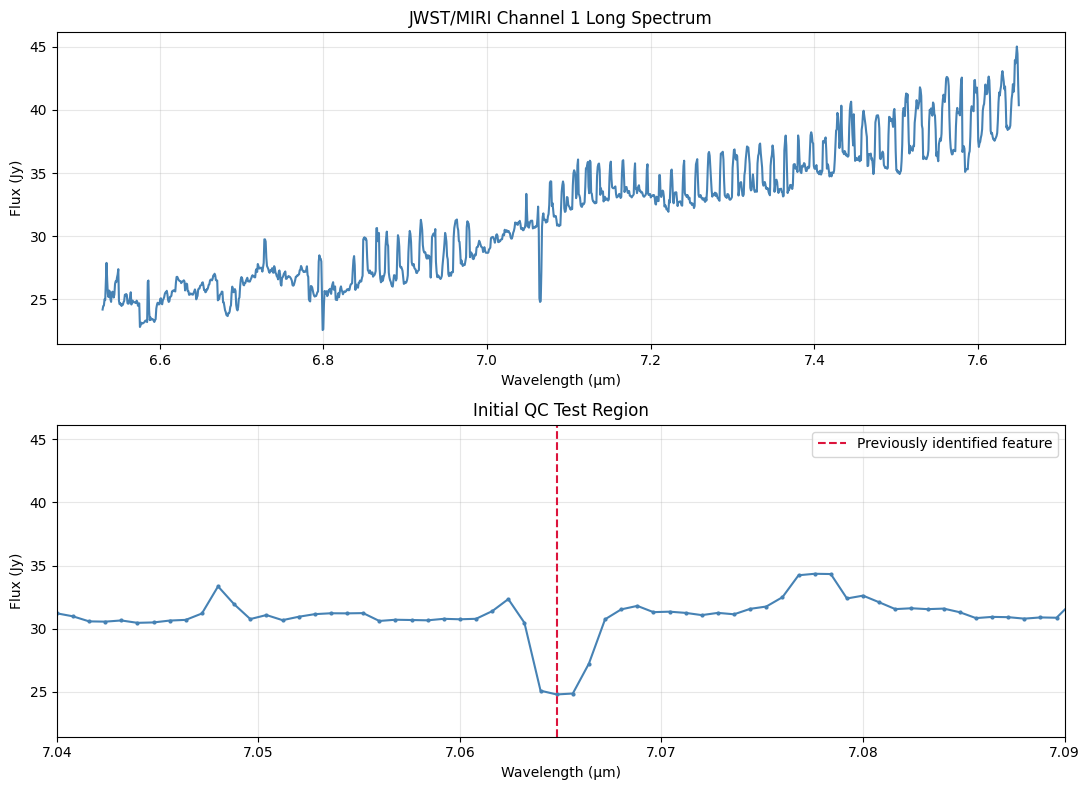

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8))

# Full Channel 1 Long spectrum
axes[0].plot(wavelength, flux, color="steelblue")
axes[0].set_title("JWST/MIRI Channel 1 Long Spectrum")
axes[0].set_xlabel("Wavelength (µm)")
axes[0].set_ylabel("Flux (Jy)")
axes[0].grid(alpha=0.3)

# Zoom in on the previously identified dip
axes[1].plot(wavelength, flux, color="steelblue", marker=".", markersize=4)
axes[1].axvline(
    7.0648,
    color="crimson",
    linestyle="--",
    label="Previously identified feature"
)

axes[1].set_xlim(7.04, 7.09)
axes[1].set_title("Initial QC Test Region")
axes[1].set_xlabel("Wavelength (µm)")
axes[1].set_ylabel("Flux (Jy)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



## 2. Automated Spectral Anomaly Detection

### 2.1 Local Median Filtering

The first QC method will identify unusual spectral features by comparing the observed flux to a local median baseline.

For each wavelength:

1. Calculate the median flux of nearby wavelength points.
2. Subtract the local median from the observed flux.
3. Calculate the residual to measure how much the observed flux differs from its surroundings.
4. Identify unusually large positive or negative residuals.

The residual is defined as:

$$
R_i = F_i - \widetilde{F}_i
$$

where:
- $R_i$ is the residual at wavelength point $i$.
- $F_i$ is the observed flux.
- $\widetilde{F}_i$ is the local median flux.

Positive residuals indicate flux above the local baseline, while negative residuals indicate flux below it.

This method provides an initial way to identify candidate anomalies without specifying their wavelengths in advance.

**Limitation:** Real astronomical spectral lines may also produce large residuals. A flagged feature is not automatically an instrumental artifact.


In [14]:
from scipy.ndimage import median_filter

# Number of wavelength points in the local window
window_size = 21

# Calculate the local median baseline
local_median = median_filter(
    flux,
    size=window_size,
    mode="reflect"
)

# Difference between observed flux and local median
residual = flux - local_median

print("Local median filter complete!")
print(f"Window size: {window_size} wavelength points")
print(f"Minimum residual: {residual.min():.4f} Jy")
print(f"Maximum residual: {residual.max():.4f} Jy")


Local median filter complete!
Window size: 21 wavelength points
Minimum residual: -5.9911 Jy
Maximum residual: 5.4363 Jy


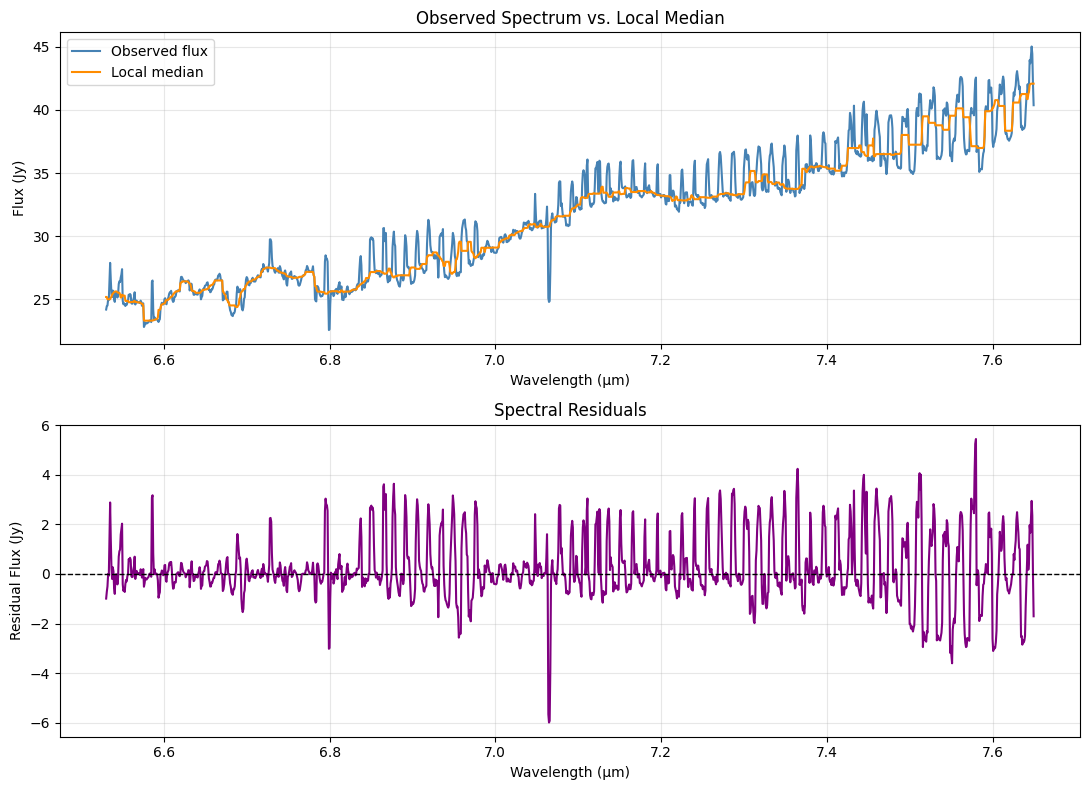

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8))

# Original spectrum and local median
axes[0].plot(
    wavelength, flux,
    color="steelblue",
    label="Observed flux"
)

axes[0].plot(
    wavelength, local_median,
    color="darkorange",
    label="Local median",
    linewidth=1.5
)

axes[0].set_title("Observed Spectrum vs. Local Median")
axes[0].set_xlabel("Wavelength (µm)")
axes[0].set_ylabel("Flux (Jy)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Residual spectrum
axes[1].plot(
    wavelength, residual,
    color="purple"
)

axes[1].axhline(
    0, color="black",
    linestyle="--",
    linewidth=1
)

axes[1].set_title("Spectral Residuals")
axes[1].set_xlabel("Wavelength (µm)")
axes[1].set_ylabel("Residual Flux (Jy)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### 2.2 Identifying Candidate Anomalies Using MAD

To automatically identify unusually large residuals, we will use the Median Absolute Deviation (MAD).

MAD measures the typical deviation of residuals from their median and is less sensitive to extreme values than standard deviation.

The robust residual scale is estimated as:

$$
\sigma_{\mathrm{robust}} = 1.4826 \times \mathrm{MAD}
$$

We will initially flag points satisfying:

$$
|R_i - \mathrm{median}(R)| > 5\sigma_{\mathrm{robust}}
$$

The threshold of 5 is an initial testing choice and will need to be evaluated.

This method identifies candidate anomalies, not confirmed instrumental artifacts. Real spectral lines and structured residuals may also exceed the threshold.


In [16]:
# Calculate the median residual
median_residual = np.median(residual)

# Calculate Median Absolute Deviation
mad = np.median(np.abs(residual - median_residual))

# Convert MAD to a robust scale estimate
robust_sigma = 1.4826 * mad

# Initial detection threshold
threshold = 5 * robust_sigma

# Flag points exceeding the threshold
anomaly_mask = np.abs(residual - median_residual) > threshold

# Get indices of flagged points
anomaly_indices = np.where(anomaly_mask)[0]

print(f"MAD: {mad:.4f} Jy")
print(f"Robust sigma: {robust_sigma:.4f} Jy")
print(f"Detection threshold: {threshold:.4f} Jy")
print(f"Number of flagged points: {len(anomaly_indices)}")
print(f"Percentage flagged: {100 * anomaly_mask.mean():.2f}%")

if robust_sigma == 0:
    print("Warning: Robust sigma is zero; threshold needs review.")


MAD: 0.4666 Jy
Robust sigma: 0.6918 Jy
Detection threshold: 3.4592 Jy
Number of flagged points: 18
Percentage flagged: 1.29%


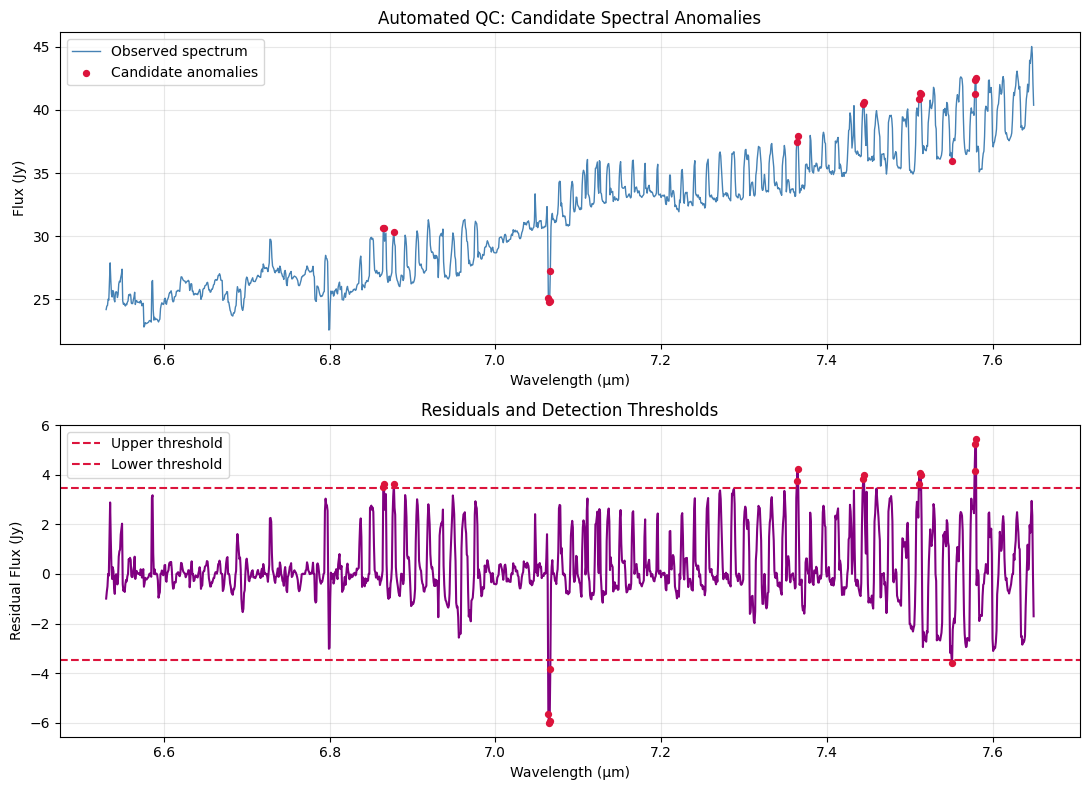

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8))

# Full spectrum with candidate anomalies
axes[0].plot(
    wavelength, flux,
    color="steelblue",
    linewidth=1,
    label="Observed spectrum"
)

axes[0].scatter(
    wavelength[anomaly_mask],
    flux[anomaly_mask],
    color="crimson",
    s=18,
    label="Candidate anomalies",
    zorder=3
)

axes[0].set_title("Automated QC: Candidate Spectral Anomalies")
axes[0].set_xlabel("Wavelength (µm)")
axes[0].set_ylabel("Flux (Jy)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Residuals with detection thresholds
axes[1].plot(wavelength, residual, color="purple")

axes[1].axhline(
    median_residual + threshold,
    color="crimson",
    linestyle="--",
    label="Upper threshold"
)

axes[1].axhline(
    median_residual - threshold,
    color="crimson",
    linestyle="--",
    label="Lower threshold"
)

axes[1].scatter(
    wavelength[anomaly_mask],
    residual[anomaly_mask],
    color="crimson",
    s=18,
    zorder=3
)

axes[1].set_title("Residuals and Detection Thresholds")
axes[1].set_xlabel("Wavelength (µm)")
axes[1].set_ylabel("Residual Flux (Jy)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### 2.3 Summarizing Detected Anomalies

The initial median-filter and MAD method identified 18 candidate anomaly points, including the previously investigated feature near 7.065 μm.

To evaluate these detections, we will create a summary table containing:

- Wavelength of each flagged point
- Observed flux and local median flux
- Residual magnitude
- Residual score relative to the robust scale
- Existing JWST data-quality (DQ) flags

This will allow us to identify the strongest deviations and compare the automated detections with the existing JWST quality flags.

The residual score is defined as:

$$
S_i = \frac{|R_i-\mathrm{median}(R)|}{\sigma_{\mathrm{robust}}}
$$

A larger score indicates a stronger deviation from the local median baseline, but does not necessarily indicate an instrumental artifact or represent a formal statistical significance.


In [18]:
import pandas as pd

# Create a table of candidate anomalies
qc_results = pd.DataFrame({
    "Wavelength (µm)": wavelength[anomaly_mask],
    "Flux (Jy)": flux[anomaly_mask],
    "Local Median (Jy)": local_median[anomaly_mask],
    "Residual (Jy)": residual[anomaly_mask],
    "Residual Score": (
        np.abs(residual[anomaly_mask] - median_residual)
        / robust_sigma
    ),
    "DQ": dq[anomaly_mask]
})

# Sort by strongest residual score
qc_results = qc_results.sort_values(
    "Residual Score",
    ascending=False
).reset_index(drop=True)

display(qc_results.round(4))


,Wavelength (µm),Flux (Jy),Local Median (Jy),Residual (Jy),Residual Score,DQ
0,7.0648,24.7887,30.7799,-5.9911,8.6597,0
1,7.0656,24.8602,30.7807,-5.9206,8.5577,0
2,7.0640,25.0844,30.7431,-5.6586,8.1791,0
3,7.5800,42.5644,37.1281,5.4363,7.8577,0
4,7.5792,42.3645,37.1281,5.2365,7.5689,0
5,7.3648,37.9704,33.7359,4.2345,6.1206,0
6,7.5784,41.2711,37.1281,4.1430,5.9884,0
7,7.5120,41.3045,37.2459,4.0586,5.8664,0
8,7.5136,41.2432,37.2459,3.9972,5.7777,0
9,7.4448,40.6530,36.6606,3.9924,5.7707,0



### 2.4 Grouping Flagged Points into Spectral Features

The initial QC method identified 18 flagged wavelength samples. However, neighboring flagged samples may belong to the same spectral feature.

For example, multiple points near 7.065 μm correspond to the previously investigated flux dip.

To avoid counting every flagged wavelength sample as a separate anomaly, we will group consecutive flagged indices into candidate spectral features.

For each group, we will record:
- The wavelength range covered by the flagged samples
- The number of flagged samples
- The wavelength of the strongest residual
- The maximum residual score
- Whether any flagged sample has a nonzero DQ value

This produces a more useful summary for reviewing candidate spectral anomalies.

**Limitation:** This initial grouping method only combines directly adjacent flagged samples. A single physical feature may be split into multiple groups if some intermediate samples fall below the detection threshold.


In [20]:
# Group consecutive flagged indices
groups = np.split(
    anomaly_indices,
    np.where(np.diff(anomaly_indices) > 1)[0] + 1
)

feature_results = []

for group in groups:
    if len(group) == 0:
        continue

    # Find the strongest residual in this group
    scores = np.abs(residual[group] - median_residual) / robust_sigma
    strongest_idx = group[np.argmax(scores)]

    feature_results.append({
        "Start (µm)": wavelength[group[0]],
        "End (µm)": wavelength[group[-1]],
        "Peak Wavelength (µm)": wavelength[strongest_idx],
        "Points": len(group),
        "Max Score": np.max(scores),
        "Peak Residual (Jy)": residual[strongest_idx],
        "Any DQ Flag": np.any(dq[group] != 0)
    })

# Create a summary table
feature_table = pd.DataFrame(feature_results)

# Sort by strongest detected feature
feature_table = feature_table.sort_values(
    "Max Score",
    ascending=False
).reset_index(drop=True)

print(f"Flagged wavelength points: {len(anomaly_indices)}")
print(f"Candidate feature groups: {len(feature_table)}")

display(feature_table.round(4))


Flagged wavelength points: 18
Candidate feature groups: 9


,Start (µm),End (µm),Peak Wavelength (µm),Points,Max Score,Peak Residual (Jy),Any DQ Flag
0,7.0640,7.0664,7.0648,4,8.6597,-5.9911,False
1,7.5784,7.5800,7.5800,3,7.8577,5.4363,False
2,7.3640,7.3648,7.3648,2,6.1206,4.2345,False
3,7.5112,7.5120,7.5120,2,5.8664,4.0586,False
4,7.5136,7.5136,7.5136,1,5.7777,3.9972,False
5,7.4440,7.4448,7.4448,2,5.7707,3.9924,False
6,6.8776,6.8776,6.8776,1,5.2508,3.6328,False
7,6.8648,6.8656,6.8656,2,5.2197,3.6112,False
8,7.5512,7.5512,7.5512,1,5.2079,-3.6030,False



### 2.5 Initial QC Results and Limitations

The initial automated QC method was tested on the JWST/MIRI Channel 1 Long X1D spectrum.

**Results:**
- 1,440 wavelength samples were analyzed.
- 18 samples exceeded the global 5-sigma robust residual threshold.
- These samples were grouped into 9 candidate spectral features.
- The strongest detected feature occurred at 7.0648 μm, with a residual of -5.9911 Jy and a residual score of 8.66.
- All flagged samples had DQ = 0 in the original X1D spectrum.

The algorithm independently detected the 7.065 μm dip previously identified during exploratory analysis.

**Current limitations:**
1. The method uses a single global threshold despite changes in spectral variability across wavelength.
2. Real astrophysical spectral features may also be flagged.
3. Adjacent-point grouping may split a single physical feature into multiple groups.
4. The method has only been tested on one spectrum.
5. The detection scores are not formal statistical significance measurements.
6. The relationship between the detected features and earlier JWST pipeline products remains unverified.

These results establish a baseline for evaluating improvements to the QC method.


In [21]:
# Divide the spectrum into 6 wavelength regions
n_regions = 6

wavelength_edges = np.linspace(
    wavelength.min(),
    wavelength.max(),
    n_regions + 1
)

region_results = []

for i in range(n_regions):

    # Select wavelengths in this region
    if i == n_regions - 1:
        mask = (
            (wavelength >= wavelength_edges[i]) &
            (wavelength <= wavelength_edges[i + 1])
        )
    else:
        mask = (
            (wavelength >= wavelength_edges[i]) &
            (wavelength < wavelength_edges[i + 1])
        )

    region_residual = residual[mask]

    # Calculate regional MAD
    region_median = np.median(region_residual)

    region_mad = np.median(
        np.abs(region_residual - region_median)
    )

    region_sigma = 1.4826 * region_mad

    region_results.append({
        "Start (µm)": wavelength_edges[i],
        "End (µm)": wavelength_edges[i + 1],
        "Points": len(region_residual),
        "MAD (Jy)": region_mad,
        "Robust Sigma (Jy)": region_sigma
    })

region_table = pd.DataFrame(region_results)

display(region_table.round(4))


,Start (µm),End (µm),Points,MAD (Jy),Robust Sigma (Jy)
0,6.5304,6.7169,234,0.1969,0.2919
1,6.7169,6.9035,233,0.2739,0.4061
2,6.9035,7.0900,233,0.4207,0.6237
3,7.0900,7.2765,233,0.4935,0.7317
4,7.2765,7.4631,233,0.7279,1.0792
5,7.4631,7.6496,234,1.6532,2.4510



## 4. Wavelength-Dependent Anomaly Detection

### 4.1 Regional MAD Thresholds

The previous analysis showed that residual variability increases substantially with wavelength.

The robust residual scale increased from approximately 0.29 Jy at shorter wavelengths to 2.45 Jy at longer wavelengths, a factor of about 8.4.

This suggests that a single global detection threshold may not characterize all wavelength regions equally.

To improve the QC method, we will calculate a separate robust threshold for each of the six wavelength regions.

For each region:

1. Calculate the median residual.
2. Calculate the regional MAD.
3. Estimate the regional robust residual scale.
4. Flag points more than five regional robust scales from the regional median.

The detection condition becomes:

$$
|R_i - \mathrm{median}(R_{\mathrm{region}})| >
5\sigma_{\mathrm{region}}
$$

This allows the threshold to adapt to changes in residual variability across the spectrum.

**Limitations:** Regional MAD values include both noise and real spectral structure. The six-region division and threshold multiplier are preliminary choices, and sharp boundaries between regions may introduce detection inconsistencies.


In [22]:
# Arrays for regional thresholds and detections
regional_threshold = np.zeros_like(residual)
regional_center = np.zeros_like(residual)
regional_anomaly_mask = np.zeros(len(residual), dtype=bool)

for i in range(n_regions):

    # Select wavelength points in the region
    if i == n_regions - 1:
        mask = (
            (wavelength >= wavelength_edges[i]) &
            (wavelength <= wavelength_edges[i + 1])
        )
    else:
        mask = (
            (wavelength >= wavelength_edges[i]) &
            (wavelength < wavelength_edges[i + 1])
        )

    region_residual = residual[mask]

    # Calculate regional statistics
    region_median = np.median(region_residual)

    region_mad = np.median(
        np.abs(region_residual - region_median)
    )

    region_sigma = 1.4826 * region_mad

    # Set regional center and threshold
    regional_center[mask] = region_median
    regional_threshold[mask] = 5 * region_sigma

    # Flag candidate anomalies
    if region_sigma > 0:
        regional_anomaly_mask[mask] = (
            np.abs(region_residual - region_median)
            > 5 * region_sigma
        )

print("Global method:", np.sum(anomaly_mask), "flagged points")
print("Regional method:", np.sum(regional_anomaly_mask), "flagged points")


Global method: 18 flagged points
Regional method: 43 flagged points


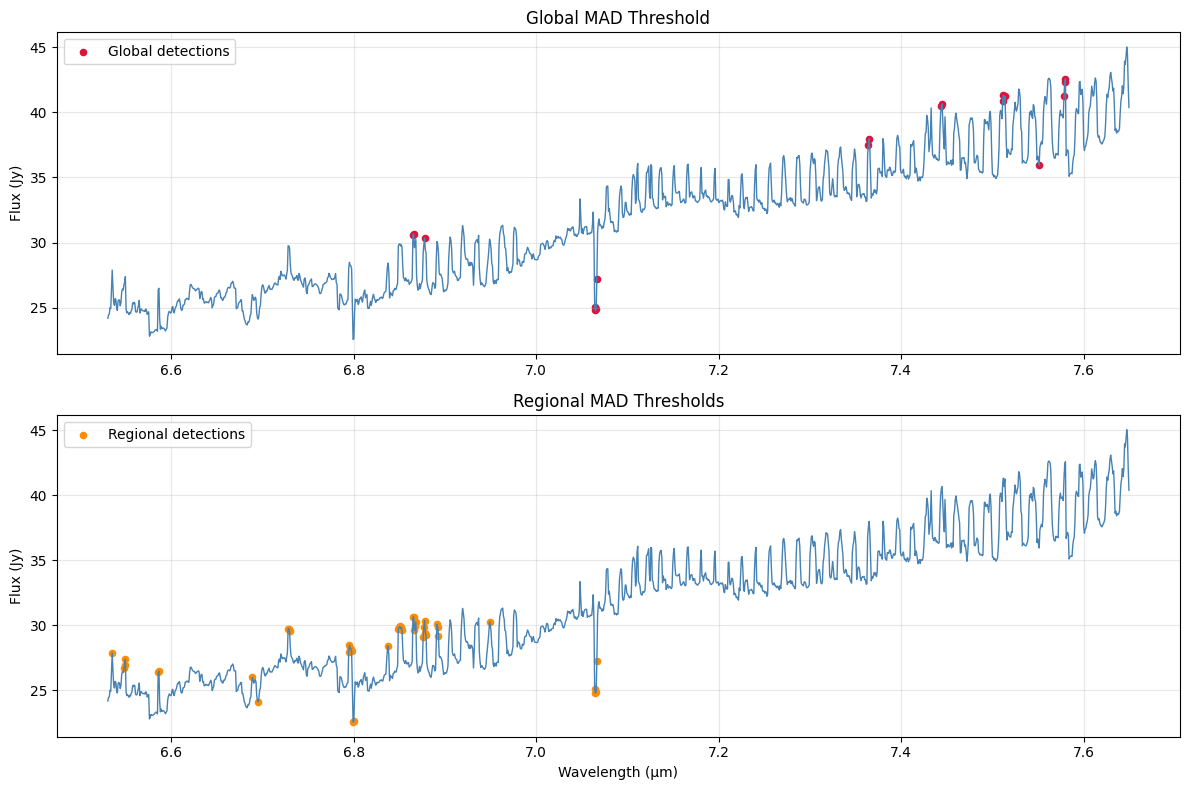

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Global threshold detections
axes[0].plot(wavelength, flux, color="steelblue", linewidth=1)
axes[0].scatter(
    wavelength[anomaly_mask],
    flux[anomaly_mask],
    color="crimson",
    s=20,
    label="Global detections"
)
axes[0].set_title("Global MAD Threshold")
axes[0].set_ylabel("Flux (Jy)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Regional threshold detections
axes[1].plot(wavelength, flux, color="steelblue", linewidth=1)
axes[1].scatter(
    wavelength[regional_anomaly_mask],
    flux[regional_anomaly_mask],
    color="darkorange",
    s=20,
    label="Regional detections"
)
axes[1].set_title("Regional MAD Thresholds")
axes[1].set_xlabel("Wavelength (µm)")
axes[1].set_ylabel("Flux (Jy)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### 4.2 Comparing Global and Regional Detection Methods

The global MAD method identified 18 candidate wavelength samples, while the regional MAD method identified 43.

The regional method detected more deviations at shorter wavelengths and fewer at longer wavelengths, consistent with the observed changes in residual variability.

To compare the methods, we will classify wavelength samples into three categories:

1. **Detected by both methods:** Samples that exceed both thresholds.
2. **Global only:** Samples detected using the global threshold but not the regional threshold.
3. **Regional only:** Samples detected using the regional threshold but not the global threshold.

This comparison will help identify which detections are sensitive to the thresholding method.

Agreement between methods does not confirm that a feature is an artifact, and disagreement does not establish that either method is incorrect.


Detected by both methods: 7
Global method only: 11
Regional method only: 36


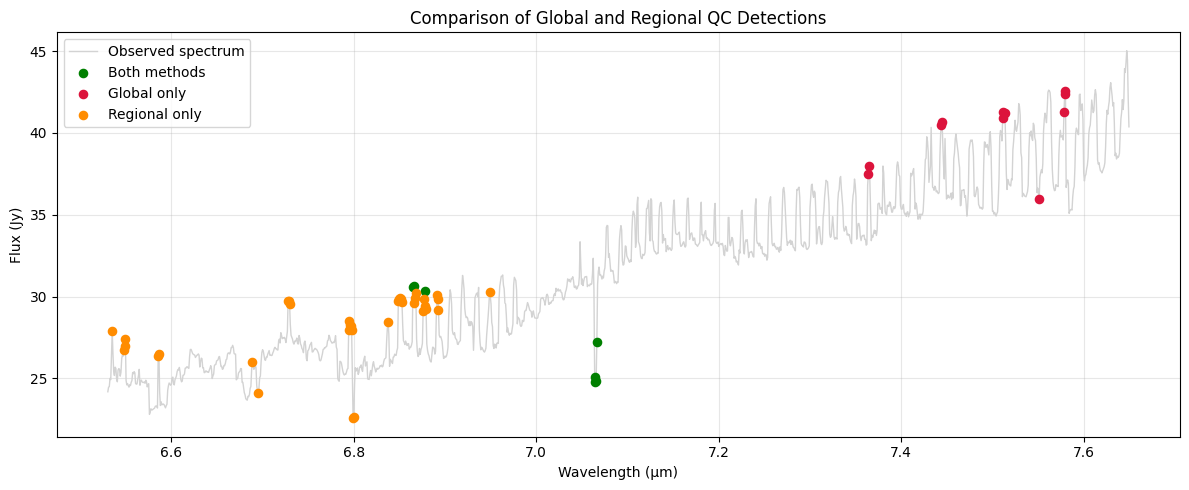

In [24]:
# Compare the two detection masks
both_methods = anomaly_mask & regional_anomaly_mask

global_only = anomaly_mask & ~regional_anomaly_mask

regional_only = regional_anomaly_mask & ~anomaly_mask

print("Detected by both methods:", np.sum(both_methods))
print("Global method only:", np.sum(global_only))
print("Regional method only:", np.sum(regional_only))

# Visualize the comparison
plt.figure(figsize=(12, 5))

plt.plot(
    wavelength, flux,
    color="lightgray",
    linewidth=1,
    label="Observed spectrum"
)

plt.scatter(
    wavelength[both_methods],
    flux[both_methods],
    color="green",
    s=35,
    label="Both methods",
    zorder=3
)

plt.scatter(
    wavelength[global_only],
    flux[global_only],
    color="crimson",
    s=35,
    label="Global only",
    zorder=3
)

plt.scatter(
    wavelength[regional_only],
    flux[regional_only],
    color="darkorange",
    s=35,
    label="Regional only",
    zorder=3
)

plt.title("Comparison of Global and Regional QC Detections")
plt.xlabel("Wavelength (µm)")
plt.ylabel("Flux (Jy)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### 4.3 Global vs. Regional Detection Results

Two MAD-based anomaly detection methods were evaluated using the Channel 1 Long X1D spectrum.

| Detection category | Flagged samples |
|---|---:|
| Global MAD method | 18 |
| Regional MAD method | 43 |
| Detected by both | 7 |
| Global only | 11 |
| Regional only | 36 |

**Key findings:**

- Both methods successfully detected the previously investigated dip near 7.065 μm.
- The global method primarily flagged large residuals at longer wavelengths.
- The regional method identified more deviations at shorter wavelengths, where the residual variability was lower.
- Only 7 wavelength samples were flagged by both methods, demonstrating substantial sensitivity to the thresholding approach.
- The existing X1D quality flags did not identify the previously investigated dip.

**Interpretation:**

The regional method accounts for changes in residual variability across the spectrum, while the global method applies a single threshold to all wavelengths.

However, neither method has been validated against confirmed instrumental artifacts. Differences in detection counts do not establish that one method is more accurate.

The current results provide a baseline for evaluating the QC workflow on additional MIRI spectra.
